# Exploratory Data Analysis (EDA) for Scraped News Data
### LimeoX AI/ML Foundation Training — Practical Lecture Notebook

**Goal:** Understand distributions, patterns, relationships, source behavior, content quality, and time-based trends before feature engineering or machine learning.

Designed for news data with fields such as `news_url_clean`, `title_clean`, `content_clean`, `published_at_utc`, `scraped_at_utc`, `author_clean`, `domain`, and optional `article_niche`/`category`.

**EDA principle:** describe and investigate the data; do not silently modify or delete records. Cleaning and validation belong in earlier pipeline stages.

## Learning outcomes

Students will learn to:
1. Profile dataset shape, schema, data types, missingness, uniqueness, and duplicates.
2. Analyze title/content lengths and source/category distributions.
3. Explore publication-time patterns and scrape delay.
4. Compare groups and inspect relationships between variables.
5. Identify suspicious extraction patterns without automatically deleting records.
6. Visualize findings and write evidence-based recommendations.

**Workflow:** Load → Profile → Univariate analysis → Grouped analysis → Time analysis → Relationships → Anomaly investigation → Findings.

## 1. Setup
Install dependencies if needed: `pip install pandas numpy matplotlib`.

In [2]:
from pathlib import Path
import json
import warnings
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

# Ignore FutureWarnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Reproducibility
RANDOM_SEED = 42

# EDA output folder
OUTPUT_DIR = Path("eda_output")
OUTPUT_DIR.mkdir(exist_ok=True)

# Environment and library information
print("=" * 50)
print("EDA ENVIRONMENT INITIALIZED")
print("=" * 50)

print("Python:", sys.version.split()[0])
print("Python Path:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

print("\nEDA setup completed successfully!")

EDA ENVIRONMENT INITIALIZED
Python: 3.15.1
Python Path: c:\Users\muham\OneDrive\Desktop\WebScraping\.venv\Scripts\python.exe
Pandas: 3.0.6
NumPy: 2.5.4
Matplotlib: 3.11.2

EDA setup completed successfully!


## 2. Load data

The loader checks likely outputs from the previous preprocessing/validation notebooks. If no CSV is found, it generates synthetic demonstration data so the notebook can run end-to-end. Synthetic data is for practice only, not real business conclusions.

In [4]:

from pathlib import Path
import pandas as pd

# Project ka exact location
PROJECT_DIR = Path(
    r"C:\Users\muham\OneDrive\Desktop\WebScraping"
)

# Actual validated CSV file
DATA_PATH = (
    PROJECT_DIR
    / "Task 4 (Validation)"
    / "validation_output"
    / "news_accepted.csv"
)

# Check file existence
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}"
    )

# Load actual dataset
df = pd.read_csv(DATA_PATH, low_memory=False)

print("=" * 60)
print("ACTUAL VALIDATED DATASET LOADED SUCCESSFULLY")
print("=" * 60)

print("File:", DATA_PATH)
print("Total Records:", f"{len(df):,}")
print("Total Columns:", df.shape[1])
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())


ACTUAL VALIDATED DATASET LOADED SUCCESSFULLY
File: C:\Users\muham\OneDrive\Desktop\WebScraping\Task 4 (Validation)\validation_output\news_accepted.csv
Total Records: 99,900
Total Columns: 15
Dataset Shape: (99900, 15)

First 5 Records:


,source_row_index,title_clean,author_clean,published_at_utc,year,time,news_url_clean,source,content_clean,domain,published_at_utc_parsed,duplicate_signature_candidate,validation_issue_count,validation_issue_codes,validation_disposition
0,0,This free app adds one of my favorite iPhone features to my Galaxy phone,Yash Wate,2026-10-26,2026.0,10:30:56,https://www.androidauthority.com/this-free-app-adds-one-of-my-favorite-iphone-features-to-my-galaxy-phone-3724833/,Android Authority,"Affiliate links on Android Authority may earn us a commission. Learn more.\nI prefer Android to iOS, and there are a...",www.androidauthority.com,2026-10-26 00:00:00+00:00,False,0,NaN,ACCEPT
1,1,Samsung slices into Apple’s iPhone Duo troubles with a cheeky new ad,Hillary Keverenge,2026-10-26,2026.0,10:44:33,https://www.androidauthority.com/samsung-mocks-iphone-duo-foldable-ad-3727862/,Android Authority,Affiliate links on Android Authority may earn us a commission. Learn more.\nA Samsung-sponsored Instagram video mock...,www.androidauthority.com,2026-10-26 00:00:00+00:00,False,0,NaN,ACCEPT
2,2,Polled readers say this core Google feature matters most to Android tablet buyers,Andy Walker,2026-10-26,2026.0,09:53:34,https://www.androidauthority.com/matters-most-android-tablet-poll-results-3727849/,Android Authority,"Affiliate links on Android Authority may earn us a commission. Learn more.\nIn early October, Amazon ruffled the fea...",www.androidauthority.com,2026-10-26 00:00:00+00:00,False,0,NaN,ACCEPT
3,3,Chrome without Google: These are the 9 best Chromium browsers,Andy Walker,2026-10-26,2026.0,09:30:56,https://www.androidauthority.com/google-chrome-alternatives-android-based-on-chromium-3726016/,Android Authority,Affiliate links on Android Authority may earn us a commission. Learn more.\nMost Android users don’t bother consider...,www.androidauthority.com,2026-10-26 00:00:00+00:00,False,0,NaN,ACCEPT
4,4,7 features I want next from Google Wallet after the Apple-inspired refresh,Andrew Grush,2026-10-26,2026.0,09:00:07,https://www.androidauthority.com/google-wallet-wanted-features-3724594/,Android Authority,Affiliate links on Android Authority may earn us a commission. Learn more.\nWe’ve recently seen several changes to G...,www.androidauthority.com,2026-10-26 00:00:00+00:00,False,0,NaN,ACCEPT


## 3. Map common field names

The mapping allows the notebook to work with several common column naming conventions without overwriting the source columns.

In [5]:
def first_existing(columns, candidates):
    return next((name for name in candidates if name in columns), None)

COLS = {
    "url": first_existing(df.columns, ["news_url_clean", "url", "news_url", "shared_url"]),
    "title": first_existing(df.columns, ["title_clean", "title", "headline"]),
    "content": first_existing(df.columns, ["content_clean", "content", "article_text", "text", "body"]),
    "published": first_existing(df.columns, ["published_at_utc", "published_at", "published_date", "publication_time"]),
    "scraped": first_existing(df.columns, ["scraped_at_utc", "scraped_at", "scrape_time", "scraped_datetime"]),
    "author": first_existing(df.columns, ["author_clean", "author", "byline"]),
    "domain": first_existing(df.columns, ["domain", "source_domain", "website"]),
    "category": first_existing(df.columns, ["article_niche", "category", "topic", "section"]),
}
print(COLS)

{'url': 'news_url_clean', 'title': 'title_clean', 'content': 'content_clean', 'published': 'published_at_utc', 'scraped': None, 'author': 'author_clean', 'domain': 'domain', 'category': None}


## 4. Dataset overview and schema
Check shape, data types, missingness, uniqueness, exact duplicate rows, and memory use.

In [6]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_non_null": df.nunique(dropna=True),
})
display(overview.sort_values("missing_pct", ascending=False))
print(f"Rows: {len(df):,} | Columns: {df.shape[1]:,}")
print("Duplicate column names:", df.columns[df.columns.duplicated()].tolist())
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Memory usage (MB):", round(df.memory_usage(deep=True).sum() / 1024**2, 2))

,dtype,non_null,missing,missing_pct,unique_non_null
validation_issue_codes,float64,0,99900,100.00,0
author_clean,str,84964,14936,14.95,4085
year,float64,99730,170,0.17,30
time,str,99730,170,0.17,32824
published_at_utc,str,99730,170,0.17,6146
published_at_utc_parsed,str,99730,170,0.17,6146
source_row_index,int64,99900,0,0.00,99900
news_url_clean,str,99900,0,0.00,99900
title_clean,str,99900,0,0.00,98286
content_clean,str,99900,0,0.00,98289


Rows: 99,900 | Columns: 15
Duplicate column names: []
Exact duplicate rows: 0
Memory usage (MB): 1028.47


## 5. Missingness and completeness
Missing values may be informative: author or publication time may be absent more often for particular sources. Missing does not automatically mean invalid.

,missing,missing_pct
validation_issue_codes,99900,100.00
author_clean,14936,14.95
year,170,0.17
time,170,0.17
published_at_utc,170,0.17
published_at_utc_parsed,170,0.17
source_row_index,0,0.00
news_url_clean,0,0.00
title_clean,0,0.00
content_clean,0,0.00


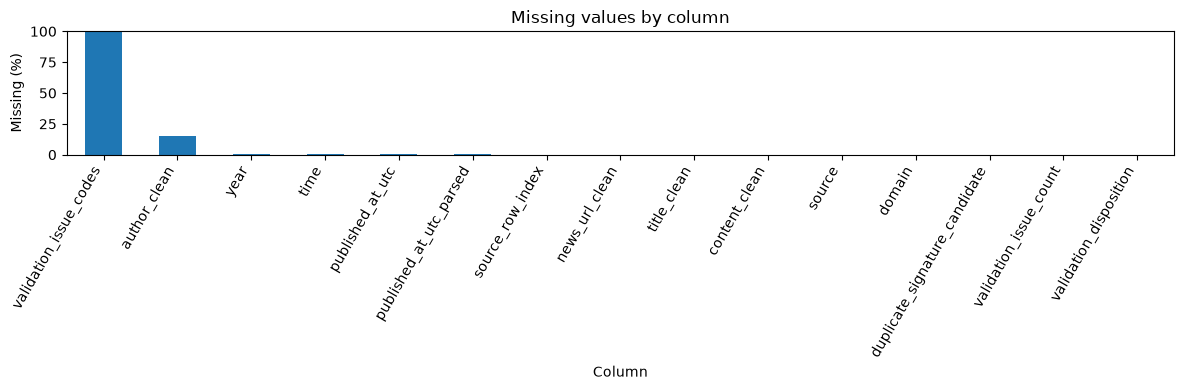

In [7]:
missing_summary = overview[["missing", "missing_pct"]].sort_values("missing_pct", ascending=False)
display(missing_summary)
ax = missing_summary["missing_pct"].plot(kind="bar", figsize=(12, 4))
ax.set_title("Missing values by column")
ax.set_ylabel("Missing (%)")
ax.set_xlabel("Column")
ax.set_ylim(0, 100)
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

In [8]:
if COLS["domain"]:
    tmp = df.copy()
    tmp["_domain_for_group"] = tmp[COLS["domain"]].fillna("(missing domain)")
    records = []
    for domain, group in tmp.groupby("_domain_for_group", dropna=False):
        row = {"domain": domain, "articles": len(group)}
        if COLS["author"]:
            row["author_missing_pct"] = group[COLS["author"]].isna().mean() * 100
        if COLS["published"]:
            row["published_missing_pct"] = group[COLS["published"]].isna().mean() * 100
        records.append(row)
    display(pd.DataFrame(records).sort_values("articles", ascending=False).round(2))
else:
    print("No domain/source field detected.")

,domain,articles,author_missing_pct,published_missing_pct
50,www.engadget.com,19964,0.03,0.00
66,www.zdnet.com,19796,21.29,0.11
4,aws.amazon.com,11956,54.04,0.00
63,www.theverge.com,11748,0.39,0.03
56,www.nasa.gov,7889,0.03,0.00
...,...,...,...,...
53,www.livescience.com,1,0.00,0.00
58,www.sciencedaily.com,1,100.00,0.00
60,www.securityweek.com,1,0.00,0.00
62,www.theguardian.com,1,0.00,0.00


## 6. Uniqueness and duplicate patterns

For news data, exact row duplicates, duplicate URLs, repeated titles, and repeated bodies are different signals. Treat them as **candidates to investigate**, not automatic deletion instructions.

In [9]:
duplicate_stats = {
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "duplicate_url_rows": int(df[COLS["url"]].duplicated(keep=False).sum()) if COLS["url"] else None,
    "duplicate_title_rows": int(df[COLS["title"]].astype("string").str.strip().duplicated(keep=False).sum()) if COLS["title"] else None,
    "duplicate_content_rows": int(df[COLS["content"]].astype("string").str.strip().duplicated(keep=False).sum()) if COLS["content"] else None,
}
display(pd.Series(duplicate_stats, name="row_count").to_frame())

,row_count
exact_duplicate_rows,0
duplicate_url_rows,0
duplicate_title_rows,2367
duplicate_content_rows,1803


In [10]:
if COLS["url"]:
    display(df[df[COLS["url"]].duplicated(keep=False)].sort_values(COLS["url"]).head(20))
if COLS["title"]:
    title_dupes = df[df[COLS["title"]].astype("string").str.strip().duplicated(keep=False)]
    cols = [c for c in [COLS["domain"], COLS["published"], COLS["title"], COLS["url"]] if c]
    display(title_dupes[cols].sort_values(COLS["title"]).head(20))

,source_row_index,title_clean,author_clean,published_at_utc,year,time,news_url_clean,source,content_clean,domain,published_at_utc_parsed,duplicate_signature_candidate,validation_issue_count,validation_issue_codes,validation_disposition


,domain,published_at_utc,title_clean,news_url_clean
37687,techcrunch.com,2020-09-17,"""Someone Here"" | TechCrunch",https://techcrunch.com/video/someone-here-2-2/
39620,techcrunch.com,2017-09-17,"""Someone Here"" | TechCrunch",https://techcrunch.com/video/someone-here-2/
24142,www.macrumors.com,2026-10-24,'Arguably Better Than Face ID': the iPhone Duo Touch ID Tip to Try,https://www.macrumors.com/2026/10/24/better-than-face-id-iphone-duo-touch-id-tip/
24280,forums.macrumors.com,2026-10-24,'Arguably Better Than Face ID': the iPhone Duo Touch ID Tip to Try,https://forums.macrumors.com/threads/arguably-better-than-face-id-the-iphone-duo-touch-id-tip-to-try.2492661/
99576,www.nasa.gov,2026-10-19,- NASA,https://www.nasa.gov/johnson/jsc-procurement/johnson-jsc-procurement-rpoc-vi/
92946,www.nasa.gov,2024-11-15,- NASA,https://www.nasa.gov/general/749791/
55693,aws.amazon.com,2026-10-16,2026 Formula 1 Chinese Grand Prix - AWS Special Program,https://aws.amazon.com/about-aws/events/f1-chinese-prix-2026-0315-shanghai/
55691,aws.amazon.com,2026-10-16,2026 Formula 1 Chinese Grand Prix - AWS Special Program,https://aws.amazon.com/about-aws/events/f1-chinese-prix-2026-0314-shanghai/
55690,aws.amazon.com,2026-10-16,2026 Formula 1 Chinese Grand Prix - AWS Special Program,https://aws.amazon.com/about-aws/events/f1-chinese-prix-2026-0313-shanghai/
67964,www.kdnuggets.com,2026-04-03,5 Useful Docker Containers for Agentic Developers,https://www.kdnuggets.com/5-useful-docker-containers-for-agentic-developers


## 7. Text-length distributions

Article length is both a content characteristic and an extraction diagnostic. Very short text may indicate failed extraction or a genuinely brief item; very long text may contain navigation, comments, or concatenated pages.

In [11]:
if COLS["title"]:
    df["_title_chars"] = df[COLS["title"]].astype("string").str.len()
    df["_title_words"] = df[COLS["title"]].astype("string").str.split().str.len()
if COLS["content"]:
    df["_content_chars"] = df[COLS["content"]].astype("string").str.len()
    df["_content_words"] = df[COLS["content"]].astype("string").str.split().str.len()

length_cols = [c for c in ["_title_chars", "_title_words", "_content_chars", "_content_words"] if c in df.columns]
display(df[length_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
_title_chars,99900.0,53.917177,23.497731,1.0,9.0,20.0,35.0,54.0,71.0,91.0,109.0,224.0
_title_words,99900.0,8.885696,4.080642,1.0,1.0,3.0,6.0,9.0,12.0,16.0,19.0,36.0
_content_chars,99900.0,3627.091471,4230.070936,81.0,211.0,333.0,752.0,2240.0,5066.0,11571.1,20000.0,273590.0
_content_words,99900.0,574.357487,664.081905,1.0,32.0,54.0,125.0,356.0,810.0,1792.0,3089.01,43336.0


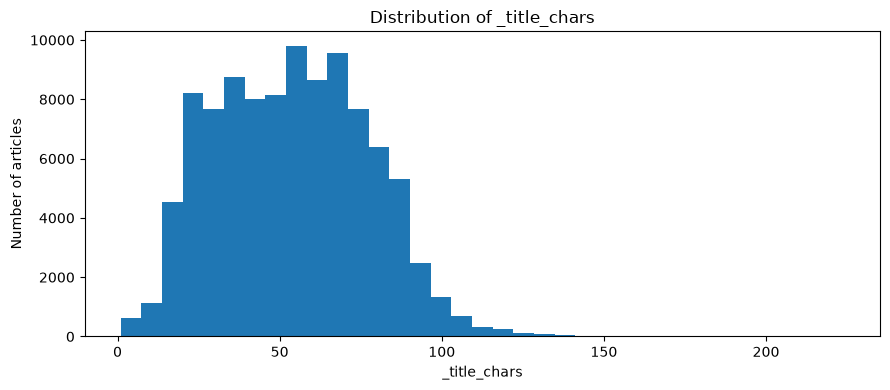

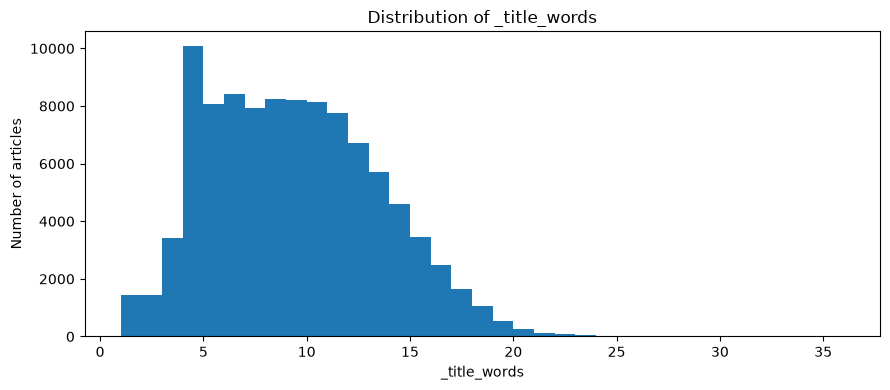

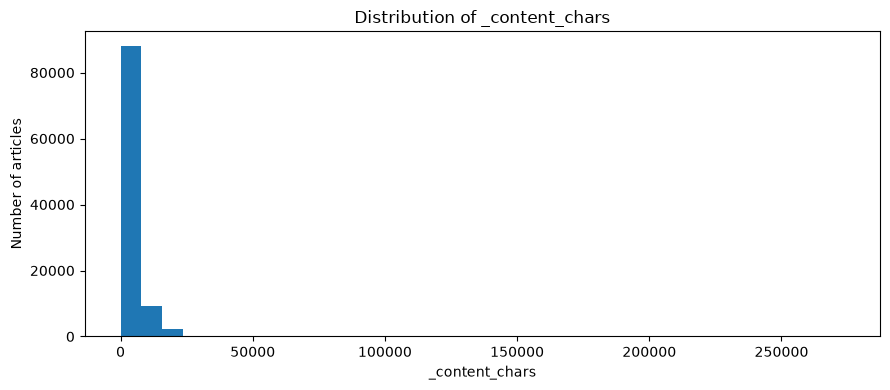

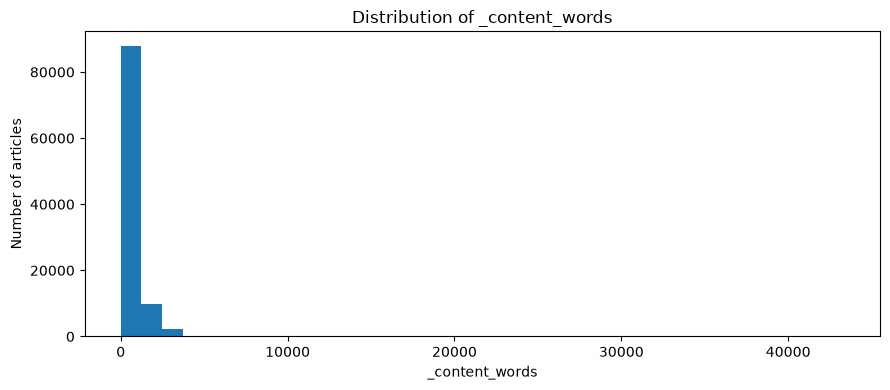

In [12]:
for col in length_cols:
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    if len(values):
        plt.figure(figsize=(9, 4))
        plt.hist(values, bins=35)
        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Number of articles")
        plt.tight_layout()
        plt.show()

In [13]:
if "_content_words" in df.columns:
    display(df.nsmallest(10, "_content_words")[[c for c in [COLS["domain"], COLS["title"], COLS["published"], "_content_words", COLS["url"]] if c]])
    display(df.nlargest(10, "_content_words")[[c for c in [COLS["domain"], COLS["title"], COLS["published"], "_content_words", COLS["url"]] if c]])

,domain,title_clean,published_at_utc,_content_words,news_url_clean
41768,about.gitlab.com,äººå·¥ç¥è½,2025-09-25,1,https://about.gitlab.com/ja-jp/the-source/ai/
40954,about.gitlab.com,AtlassianããGitLabã¸ã®ç§»è¡,2026-10-12,3,https://about.gitlab.com/ja-jp/move-to-gitlab-from-atlassian/
41791,about.gitlab.com,ãã©ãããã©ã¼ã ã¨ã¤ã³ãã©ã¹ãã©ã¯ãã£,2025-09-25,4,https://about.gitlab.com/ja-jp/the-source/platform/
42907,about.gitlab.com,Stephen Walters,2025-07-03,4,https://about.gitlab.com/ja-jp/the-source/authors/stephen-walters/
40968,about.gitlab.com,The Sourceï¼ã½ããã¦ã§ã¢éçºã®æªæ¥ã¸ã®æ´å¯,2025-07-02,5,https://about.gitlab.com/ja-jp/the-source/
41811,about.gitlab.com,GitLab 17.8ã®æ°æ©è½,2026-05-14,5,https://about.gitlab.com/ja-jp/whats-new/17-8/
41812,about.gitlab.com,GitLab 17.10ã®æ°æ©è½,2026-07-24,5,https://about.gitlab.com/ja-jp/whats-new/17-10/
40950,about.gitlab.com,GitLab Orbit: AIã¨ã¼ã¸ã§ã³ãã®ããã®ã³ã³ãã­ã¹ãã¬ã¤ã¤ã¼,2026-10-14,6,https://about.gitlab.com/ja-jp/gitlab-orbit/
41792,about.gitlab.com,ã»ã­ã¥ãªãã£ã¨ã³ã³ãã©ã¤ã¢ã³ã¹,2025-09-25,6,https://about.gitlab.com/ja-jp/the-source/security/
41814,about.gitlab.com,GitLab 18.0ã®æ°æ©è½,2026-05-14,6,https://about.gitlab.com/ja-jp/whats-new/18-0/


,domain,title_clean,published_at_utc,_content_words,news_url_clean
61809,aws.amazon.com,AWS Service Terms,2026-10-22,43336,https://aws.amazon.com/service-terms/
57747,aws.amazon.com,Amazon EC2 FAQs,2026-10-16,40939,https://aws.amazon.com/ec2/faqs/
61074,aws.amazon.com,Amazon RDS FAQs,2026-10-16,15898,https://aws.amazon.com/rds/faqs/
56713,aws.amazon.com,FAQs,2026-10-16,14891,https://aws.amazon.com/cloudfront/faqs/
62077,aws.amazon.com,FAQs,2026-10-16,11773,https://aws.amazon.com/storagegateway/faqs/
56302,aws.amazon.com,FAQs,2026-10-16,11608,https://aws.amazon.com/aws-transfer-family/faqs/
60131,aws.amazon.com,FAQ,2026-10-16,10094,https://aws.amazon.com/windows/faq/
55987,aws.amazon.com,S3 FAQs All,2026-10-16,9747,https://aws.amazon.com/s3/faqs/
59815,aws.amazon.com,Lightsail FAQs,2026-10-22,9654,https://aws.amazon.com/lightsail/faq/
62007,aws.amazon.com,FAQs,2026-10-16,9643,https://aws.amazon.com/sns/faqs/


## 8. Source/domain distribution
Inspect which domains contribute most, whether the data is concentrated in a few sites, and how article lengths vary by source.

,articles
domain,
www.engadget.com,19964
www.zdnet.com,19796
aws.amazon.com,11956
www.theverge.com,11748
www.nasa.gov,7889
about.gitlab.com,6167
mashable.com,4903
github.blog,4743
techcrunch.com,4058


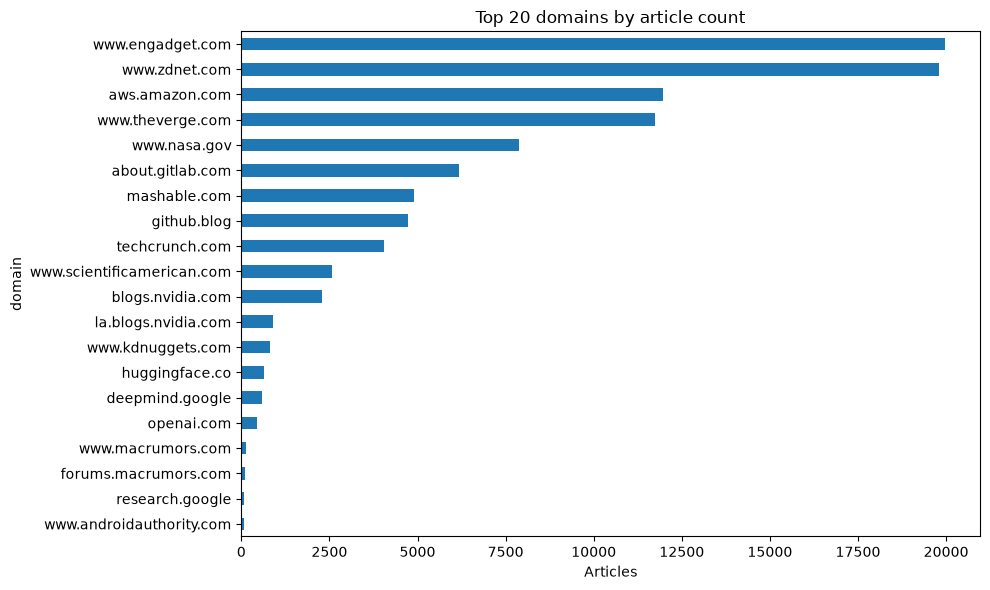

,share_pct
domain,
www.engadget.com,19.98
www.zdnet.com,19.82
aws.amazon.com,11.97
www.theverge.com,11.76
www.nasa.gov,7.90
about.gitlab.com,6.17
mashable.com,4.91
github.blog,4.75
techcrunch.com,4.06


In [14]:
if COLS["domain"]:
    source_counts = df[COLS["domain"]].fillna("(missing domain)").value_counts()
    display(source_counts.rename("articles").to_frame().head(30))
    ax = source_counts.head(20).sort_values().plot(kind="barh", figsize=(10, 6))
    ax.set_title("Top 20 domains by article count")
    ax.set_xlabel("Articles")
    plt.tight_layout()
    plt.show()
    display((source_counts / source_counts.sum() * 100).rename("share_pct").to_frame().head(20).round(2))
else:
    print("No domain/source field detected.")

In [15]:
if COLS["domain"] and "_content_words" in df.columns:
    source_length = df.groupby(COLS["domain"], dropna=False).agg(
        articles=("_content_words", "size"),
        median_content_words=("_content_words", "median"),
        mean_content_words=("_content_words", "mean"),
        p95_content_words=("_content_words", lambda s: s.quantile(.95)),
    )
    display(source_length.query("articles >= 3").sort_values("articles", ascending=False).round(1).head(30))

,articles,median_content_words,mean_content_words,p95_content_words
domain,,,,
www.engadget.com,19964,116.0,217.2,770.0
www.zdnet.com,19796,700.0,752.3,1783.0
aws.amazon.com,11956,258.0,629.0,2102.2
www.theverge.com,11748,275.5,499.6,1848.6
www.nasa.gov,7889,451.0,692.6,2749.2
about.gitlab.com,6167,794.0,908.4,2351.1
mashable.com,4903,323.0,378.0,676.9
github.blog,4743,120.0,205.0,631.7
techcrunch.com,4058,435.0,454.6,620.0


## 9. Category/niche distribution
Class imbalance matters for classification, recommendation, and topic reporting. Inspect category labels before building models.

In [18]:
if COLS["category"]:
    category_counts = df[COLS["category"]].fillna("(missing category)").value_counts()
    display(category_counts.rename("articles").to_frame())
    ax = category_counts.head(25).sort_values().plot(kind="barh", figsize=(10, 6))
    ax.set_title("Article count by category/niche")
    ax.set_xlabel("Articles")
    plt.tight_layout()
    plt.show()
else:
    print("No category/niche field detected.")

No category/niche field detected.


## 10. Publication-time patterns

Convert timestamps to UTC explicitly. Invalid or missing timestamps become `NaT` and are counted. Explore coverage, articles per day/hour, weekday patterns, and publication-to-scrape delay.

**Caution:** scraper schedules, source timezone conventions, and incomplete history can create apparent trends.

Valid publication timestamps: 99730 / 99900
Earliest: 1997-01-16 00:00:00+00:00 | Latest: 2026-10-26 00:00:00+00:00
Coverage days: 10875.0


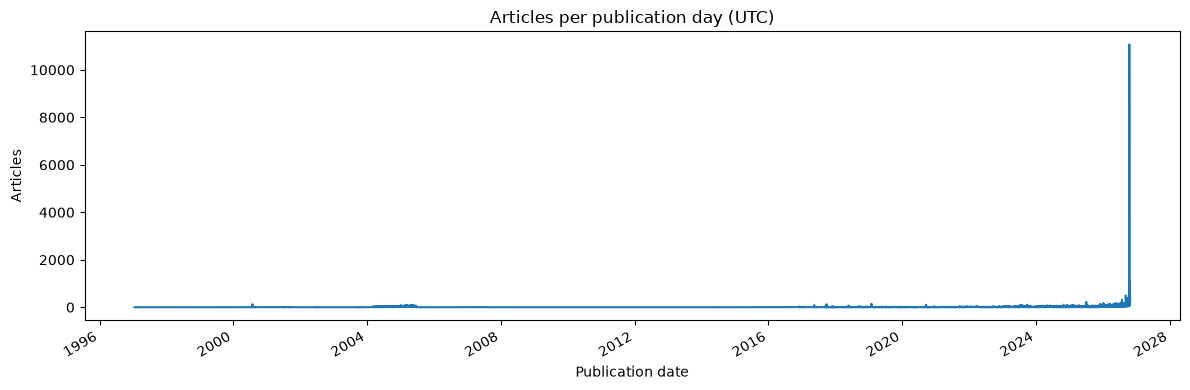

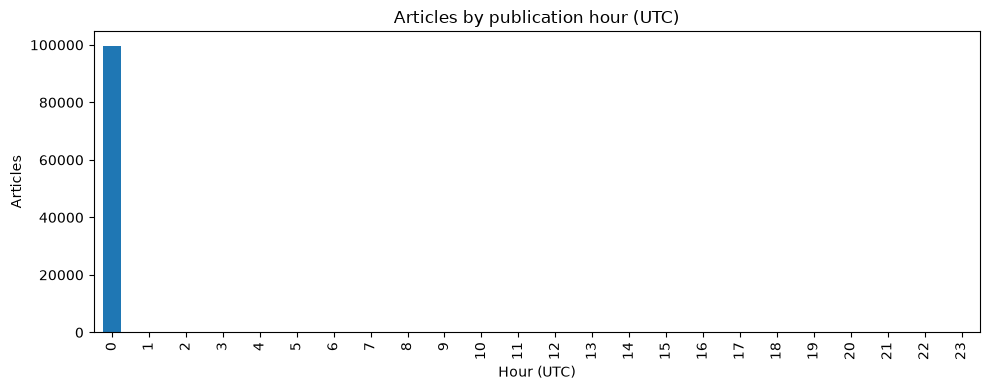

,articles
_published_day_name,
Monday,14319
Tuesday,18039
Wednesday,17057
Thursday,18147
Friday,24776
Saturday,4236
Sunday,3156


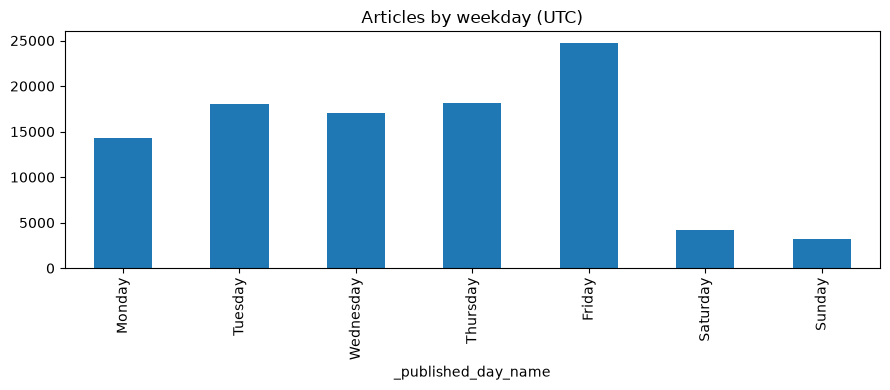

In [19]:
if COLS["published"]:
    df["_published_dt"] = pd.to_datetime(df[COLS["published"]], errors="coerce", utc=True)
    valid_pub = df["_published_dt"].dropna()
    print("Valid publication timestamps:", len(valid_pub), "/", len(df))
    if len(valid_pub):
        print("Earliest:", valid_pub.min(), "| Latest:", valid_pub.max())
        print("Coverage days:", round((valid_pub.max() - valid_pub.min()).total_seconds() / 86400, 2))
        df["_published_date"] = df["_published_dt"].dt.floor("D")
        df["_published_hour_utc"] = df["_published_dt"].dt.hour
        df["_published_day_name"] = df["_published_dt"].dt.day_name()
        daily = df.groupby("_published_date").size()
        ax = daily.plot(figsize=(12, 4))
        ax.set_title("Articles per publication day (UTC)")
        ax.set_xlabel("Publication date")
        ax.set_ylabel("Articles")
        plt.tight_layout()
        plt.show()
        hourly = df["_published_hour_utc"].value_counts().sort_index().reindex(range(24), fill_value=0)
        ax = hourly.plot(kind="bar", figsize=(10, 4))
        ax.set_title("Articles by publication hour (UTC)")
        ax.set_xlabel("Hour (UTC)")
        ax.set_ylabel("Articles")
        plt.tight_layout()
        plt.show()
        order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
        weekdays = df["_published_day_name"].value_counts().reindex(order, fill_value=0)
        display(weekdays.rename("articles").to_frame())
        weekdays.plot(kind="bar", figsize=(9, 4), title="Articles by weekday (UTC)")
        plt.tight_layout()
        plt.show()
else:
    print("No publication timestamp field detected.")

In [20]:
if COLS["published"] and COLS["scraped"]:
    df["_scraped_dt"] = pd.to_datetime(df[COLS["scraped"]], errors="coerce", utc=True)
    df["_publish_to_scrape_minutes"] = (df["_scraped_dt"] - df["_published_dt"]).dt.total_seconds() / 60
    display(df["_publish_to_scrape_minutes"].describe(percentiles=[.01, .05, .5, .95, .99]).to_frame())
    print("Negative publication-to-scrape delays:", int((df["_publish_to_scrape_minutes"] < 0).sum()))
    delay = df["_publish_to_scrape_minutes"].dropna()
    if len(delay):
        clipped = delay.clip(lower=delay.quantile(.01), upper=delay.quantile(.99))
        plt.figure(figsize=(9, 4))
        plt.hist(clipped, bins=40)
        plt.title("Publication-to-scrape delay (clipped to 1st–99th percentile)")
        plt.xlabel("Minutes")
        plt.ylabel("Articles")
        plt.tight_layout()
        plt.show()
else:
    print("Both publication and scrape timestamps are required for scrape-delay analysis.")

Both publication and scrape timestamps are required for scrape-delay analysis.


## 11. Relationships between variables
Compare title length with article length and inspect category mix by domain. Correlation is descriptive, not causal.

Pearson correlation: 0.187
Spearman correlation: 0.349


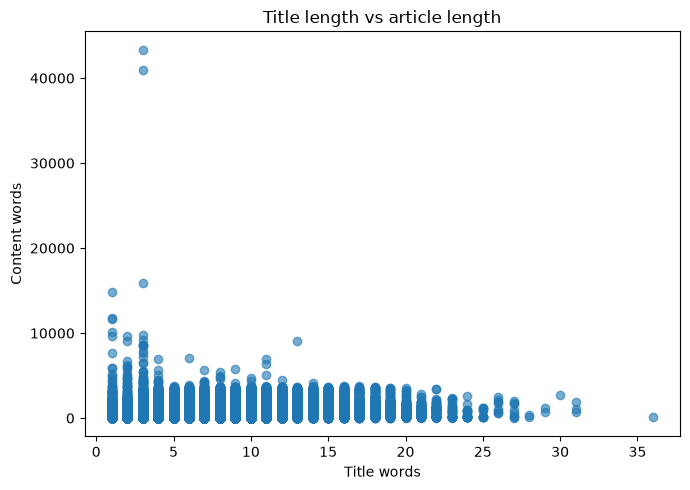

In [21]:
if "_title_words" in df.columns and "_content_words" in df.columns:
    pair = df[["_title_words", "_content_words"]].dropna()
    if len(pair) >= 2:
        print("Pearson correlation:", round(pair.corr(method="pearson").iloc[0, 1], 3))
        print("Spearman correlation:", round(pair.corr(method="spearman").iloc[0, 1], 3))
        plt.figure(figsize=(7, 5))
        plt.scatter(pair["_title_words"], pair["_content_words"], alpha=.6)
        plt.title("Title length vs article length")
        plt.xlabel("Title words")
        plt.ylabel("Content words")
        plt.tight_layout()
        plt.show()

In [22]:
if COLS["domain"] and COLS["category"]:
    mix = pd.crosstab(df[COLS["domain"]], df[COLS["category"]], normalize="index") * 100
    display(mix.round(1).head(25))
    ax = mix.head(15).plot(kind="bar", stacked=True, figsize=(12, 6))
    ax.set_title("Category composition by domain (%)")
    ax.set_ylabel("Share within domain (%)")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()

## 12. Investigate suspicious extraction patterns

The heuristics below flag candidates for manual review. Thresholds are starting points, not universal rules. Do not automatically delete short/long articles.

In [24]:

suspicious = pd.Series(False, index=df.index)

# 1. Very short articles
if "_content_words" in df.columns:
    suspicious |= df["_content_words"].fillna(0).lt(40)

    # 2. Extremely long articles (above 99th percentile)
    if df["_content_words"].notna().any():
        suspicious |= df["_content_words"].gt(
            df["_content_words"].quantile(0.99)
        )

# 3. Suspicious or error-like titles
if COLS["title"]:
    pattern = (
        r"access denied|captcha|robot check|page not found|"
        r"403 forbidden|enable javascript"
    )
    suspicious |= (
        df[COLS["title"]]
        .astype("string")
        .str.contains(pattern, case=False, na=False)
    )

# 4. Publication-to-scraping time check (only if available)
if "_publish_to_scrape_minutes" in df.columns:
    suspicious |= (
        df["_publish_to_scrape_minutes"].lt(0).fillna(False)
    )

# 5. Safely select available columns
review_cols = [
    c for c in [
        COLS["domain"],
        COLS["title"],
        COLS["published"],
        COLS["scraped"],
        "_title_words",
        "_content_words",
        "_publish_to_scrape_minutes",
        COLS["url"]
    ]
    if c and c in df.columns
]

suspicious_records = df.loc[suspicious, review_cols].copy()

print(
    f"Suspicious candidates: {len(suspicious_records):,} / "
    f"{len(df):,} ({len(suspicious_records)/max(len(df), 1):.1%})"
)

display(suspicious_records.head(50))


Suspicious candidates: 3,356 / 99,900 (3.4%)


,domain,title_clean,published_at_utc,_title_words,_content_words,news_url_clean
78,deepmind.google,Veo 3.1,2026-06-04,2,5626,https://deepmind.google/models/veo/
114,deepmind.google,Gemini Robotics On-Device 2,2026-07-30,4,28,https://deepmind.google/models/gemini-robotics/on-device/
123,deepmind.google,Nano Banana Pro,2026-06-29,3,3652,https://deepmind.google/models/gemini-image/pro/
125,deepmind.google,Nano Banana 2.1,2026-10-06,3,7923,https://deepmind.google/models/gemini-image/flash/
131,deepmind.google,Genie 3,2026-05-19,2,3749,https://deepmind.google/models/genie/
256,deepmind.google,"Societal and technological progress as sewing an ever-growing, ever-changing, patchy, and polychrome quilt",2025-04-22,13,37,https://deepmind.google/research/publications/155313/
408,deepmind.google,News,NaN,1,14,https://deepmind.google/blog/
413,deepmind.google,2023: A Year of Groundbreaking Advances in AI and Computing,2023-12-22,10,4663,https://deepmind.google/blog/2023-a-year-of-groundbreaking-advances-in-ai-and-computing/
522,deepmind.google,Agent57: Outperforming the human Atari benchmark,2020-03-31,6,3156,https://deepmind.google/blog/agent57-outperforming-the-human-atari-benchmark/
585,deepmind.google,FermiNet: Quantum physics and chemistry from first principles,2024-08-22,8,3137,https://deepmind.google/blog/ferminet-quantum-physics-and-chemistry-from-first-principles/


## 13. Optional numeric correlation matrix
Use only numeric features; avoid IDs and encoded identifiers.

,source_row_index,year,validation_issue_count,validation_issue_codes,_title_chars,_title_words,_content_chars,_content_words,_published_hour_utc
source_row_index,1.00,0.18,NaN,NaN,0.01,-0.02,0.13,0.12,NaN
year,0.18,1.00,NaN,NaN,0.39,0.35,0.33,0.32,NaN
validation_issue_count,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
validation_issue_codes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
_title_chars,0.01,0.39,NaN,NaN,1.00,0.91,0.14,0.16,NaN
_title_words,-0.02,0.35,NaN,NaN,0.91,1.00,0.13,0.19,NaN
_content_chars,0.13,0.33,NaN,NaN,0.14,0.13,1.00,0.97,NaN
_content_words,0.12,0.32,NaN,NaN,0.16,0.19,0.97,1.00,NaN
_published_hour_utc,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


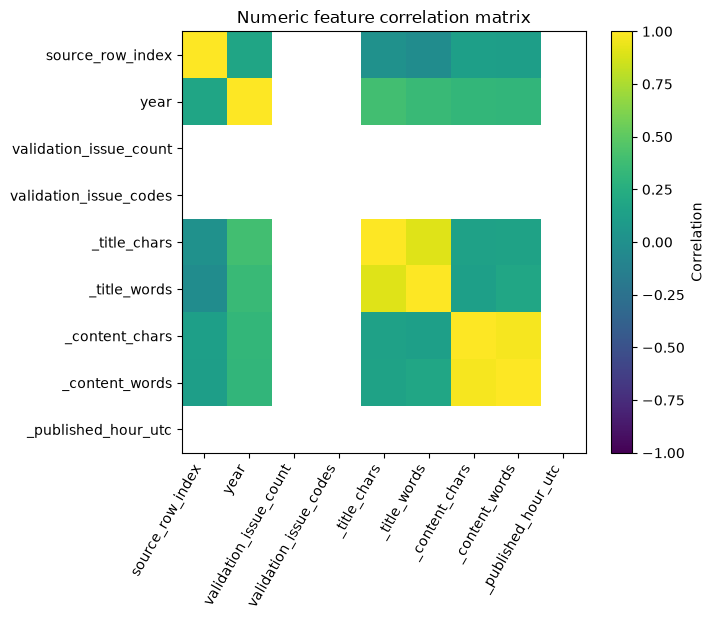

In [25]:
numeric = df.select_dtypes(include=np.number)
if numeric.shape[1] >= 2:
    corr = numeric.corr(numeric_only=True)
    display(corr.round(2))
    fig, ax = plt.subplots(figsize=(max(6, len(corr.columns)*.8), max(5, len(corr.columns)*.7)))
    image = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=60, ha="right")
    ax.set_yticks(range(len(corr.index)))
    ax.set_yticklabels(corr.index)
    ax.set_title("Numeric feature correlation matrix")
    fig.colorbar(image, ax=ax, label="Correlation")
    plt.tight_layout()
    plt.show()
else:
    print("Fewer than two numeric columns are available.")

## 14. Export EDA outputs
Summaries and candidate records are exported for review. The original source dataset is not overwritten.

In [26]:
overview.to_csv(OUTPUT_DIR / "column_profile.csv")
missing_summary.to_csv(OUTPUT_DIR / "missingness_summary.csv")
pd.Series(duplicate_stats, name="row_count").to_csv(OUTPUT_DIR / "duplicate_summary.csv")
if "source_counts" in globals():
    source_counts.rename("articles").to_csv(OUTPUT_DIR / "source_distribution.csv")
if "category_counts" in globals():
    category_counts.rename("articles").to_csv(OUTPUT_DIR / "category_distribution.csv")
suspicious_records.to_csv(OUTPUT_DIR / "suspicious_candidates.csv", index=False)
summary = {
    "rows": int(len(df)),
    "columns": int(df.shape[1]),
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "missing_pct_by_column": {str(k): float(v) for k, v in overview["missing_pct"].items()},
    "detected_fields": COLS,
    "outputs_directory": str(OUTPUT_DIR.resolve()),
}
with open(OUTPUT_DIR / "eda_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
print("Saved outputs to:", OUTPUT_DIR.resolve())
print(sorted(p.name for p in OUTPUT_DIR.iterdir()))

Saved outputs to: C:\Users\muham\Downloads\eda_output
['column_profile.csv', 'duplicate_summary.csv', 'eda_summary.json', 'missingness_summary.csv', 'source_distribution.csv', 'suspicious_candidates.csv']


## 15. How to write EDA findings

For each finding, record:
1. **Observation:** What does the chart/table show?
2. **Evidence:** A count, percentage, median, range, or comparison.
3. **Interpretation:** What might explain the pattern?
4. **Caveat:** What else could explain it?
5. **Action:** Investigate, validate, collect more data, or design a feature.

**Illustrative example only:** “One source contributes 38% of rows. This may overrepresent that publisher, although it could reflect genuine publishing volume or the scraper schedule. Compare source coverage over time before deciding whether source balancing is needed.” Do not copy illustrative numbers as your own results.

## 16. Student exercises

1. Find the top three domains and calculate their combined share of articles.
2. Compare median content length across the five largest domains.
3. Compare missing author and publication-time percentages by domain.
4. Plot daily article counts and identify gaps or spikes; suggest two explanations.
5. Investigate repeated titles across different domains: syndication or scraper duplication?
6. Select one suspicious record and document why it deserves review.
7. Write five findings using observation → evidence → interpretation → caveat → action.
8. Explain why automatically deleting every short article or repeated title is unsafe.

## Key takeaways and next lecture

- EDA reveals structure, distributions, missingness, duplicates, source concentration, temporal patterns, and relationships.
- Source and time analyses can expose collection bias and scraper reliability issues.
- Suspicious rows are review candidates, not automatically invalid records.
- Keep EDA separate from data cleaning and log evidence-based findings.

**Recommended next lecture:** Feature Engineering for News/Text Data — converting validated articles into meaningful numerical and categorical signals before embeddings and machine learning.